# Boosting - ADABOOST


<!-- TOC START min:2 max:4 link:true asterisk:true update:true -->
* [What you will learn in this class](#what-you-will-learn-in-this-class)
* [Introduction](#introduction)
* [AdaBoost](#adaboost)
  * [Algorithm](#algorithm)
  * [Performance Condition](#performance-condition)
  * [Adaboost's overfitting](#adaboost--overfitting)
  * [Margins](#margins)
<!-- TOC END -->



## What you will learn in this class

Here we define boosting. Boosting improves the performance of a simple supervised Machine Learning model by repeating the learning step several times in a row, each time taking the previous prediction errors into account, and then combining the different models. This method uses the notion of "aggregating" that we saw previously.

## Introduction

Boosting algorithms aim to turn weak predictors into a strong predictor: starting from models that are only partially correlated with the true distribution of the data, they build a new model that can approach this distribution as closely as desired.

Many boosting algorithms exist, but the first major breakthrough in this field was the AdaBoost method, invented by Schapire and Freund, who won the prestigious Gödel Prize in computer science for it in 2003.

Imagine you are preparing for an extremely difficult exam. You have read through the chapters of your course once, and you test your knowledge on past exam questions. Your score on this first mock exam tells you which parts of the course you know well, and which ones need a little more work. How will you plan your second round of studying based on this first attempt? You will probably go through the content again and spend a little more time on what you had more difficulties with, and a little less time on the chapters you got right the first time. Boosting follows exactly the same logic.

The general idea of the AdaBoost method is to build models one after the other, each one a sufficiently good predictor, by changing the weights given to the observations: we increase the importance of the observations that are misclassified, and reduce the importance of those that are correctly classified. In the end, the models are aggregated, and the weight of each model depends on its training error.

## AdaBoost

### Algorithm

The simplest way to introduce the AdaBoost method is to describe its algorithm in pseudo-code. We consider a modeling problem with observations $X_1,...,X_i,...,X_n$ (vectors whose elements are the values of the explanatory variables) and a binary target variable $Y\in\{-1,+1\}$.

The algorithm is written as follows:

**Initialization:**

$D_{1}(i)=\frac{1}{n}\;\text{for}\;i\in\{1,\dots,n\}$
At the start, the AdaBoost algorithm gives the same weight to all observations.


**For** $t\;\in[1,T]$ **:**

* Train a model on the training data by weighting the observations with $D_t$

* We get a predictor that we write $h_t:\;X\rightarrow\{-1,+1\}$

* We compute the weighted prediction error:

$\epsilon_t=\sum_{i=1}^{n}D_t(i)\cdot1[h_t(X_i)\neq{Y_i}]$ (the weights $D_t$ sum to 1)

* We compute:

 $\alpha_t=\frac{1}{2}ln(\frac{1-\epsilon_t}{\epsilon_t})$, the weight of this model in the final aggregation

* We update the observation weights:

$D_{t+1}(i)=\frac{D_t(i)exp(-\alpha_t{Y_i}h_t(X_i))}{Z_t}$


where $Z_t$ is simply the normalization factor such that

$\sum_{i=1}^{n}D_{t+1}(i)=1$


**Result:** the final model obtained from the AdaBoost algorithm is the following:


$H(X)=sign(\sum_{t=1}^{T}\alpha_t{h_t}(X))=sign(F(x))$


So we start by giving the same weight to all observations. Then we build prediction models one after the other (for example logistic regressions). At each iteration, we change the weights of the observations, and these weights influence how the model parameters are optimized. The weights of the observations that were badly predicted increase, and the weights of the observations that were well predicted decrease. This forces the next model to pay more attention to the observations that the previous model found hard to predict. In the end, the final model is a weighted vote of the different models, based on their individual performance on the training data. Models that performed better get more weight in the vote than models that performed worse.



### Performance Condition

Intuitively, a binary classification model needs three characteristics to be efficient and accurate:


* It must have been trained on a sufficient number of examples
* It must describe the observations of the training set accurately, i.e. the training error must be small.
* It must be simple (a common idea in statistics is that, in general, a simple model has a better chance of performing well on new data than a complex one; this idea is often called Ockham's razor).

These essential conditions need to be formalized mathematically to be of practical use. It is rather difficult to say in advance exactly how many observations make a training set large enough: it depends on the relative proportions of positive and negative observations, and on the type of model we want to use with the AdaBoost method. For example, we will probably need fewer observations to correctly optimize a logistic regression (this does not guarantee good results, but at least the parameters will converge), and more observations if our binary classification model is more complex, such as a neural network.

The second performance criterion, commonly called the _weak learning condition_, is the idea that each binary classification model in the final model must have a training error smaller than pure chance. Mathematically, this means that:

$\epsilon_t\;<\frac{1}{2}-\gamma$

where $\gamma\;>0$.

Note that this specific criterion assumes that the observations are equally split between the two classes. In general, this criterion can be written:

$\epsilon_t\;<\;\text{baseline error}-\gamma$, where $\gamma>0$



### Overfitting AdaBoost

Once these two conditions are met, the AdaBoost algorithm brings the training error down to a minimal level in relatively few iterations. However, as is often the case in statistics, a minimal training error often means overfitting: the model sticks too closely to the training data. The figure below shows how the errors evolve as boosting rounds are added:


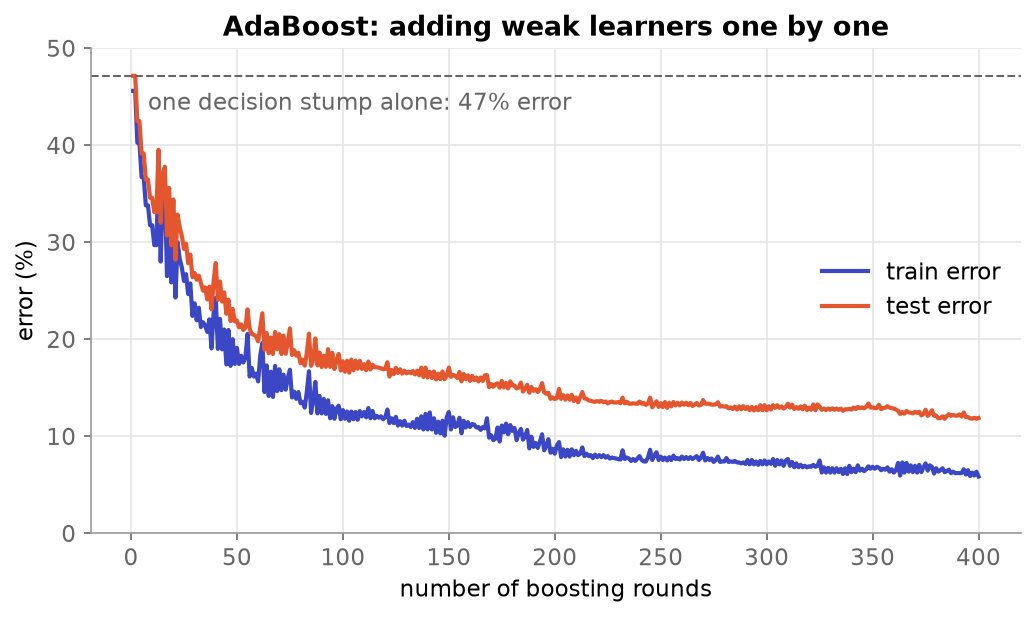


Both errors drop quickly at first, then the training error keeps decreasing faster than the test error, and a gap opens between them. If too many iterations are performed, the test error can stop improving, or even increase again: the model is overfitting.



### Margins

We have seen above that the AdaBoost algorithm sometimes produces an overfitted model, i.e. a model that performs very well, or even perfectly, on the training data, but gives sub-optimal results on the validation data. However, it does not always fall into that trap. There are cases where the final model predicts the validation data better and better as the number of iterations increases. There is even a theoretical framework in which AdaBoost gives a model whose error on the validation sample reaches an optimal level!

To explain this theoretical framework, we introduce the notion of margin. Our model aggregates weak learners, and its predictions come from a weighted vote. Depending on the result of the vote, we will not necessarily have the same confidence in the prediction for every observation. Just as in a real-world election, we are more likely to trust a decision that wins a large majority of the votes than one that wins a small majority. Behind this idea of a strong or weak majority is the notion of margin. The margin of an observation is a value between -1 and 1, defined as follows:


$\text{margin}(X_i)=\dfrac{\sum_{t:\,h_t(X_i)=Y_i}\alpha_t\;-\;\sum_{t:\,h_t(X_i)\neq Y_i}\alpha_t}{\sum_{t}\alpha_t}$


It is the difference between the total weight of the models that predict correctly and the total weight of the models that are wrong.

This concept of margin is essential. It can be shown that the model produced by AdaBoost, and more generally any model based on a majority vote of elementary models, has a generalization error (error on the validation set) that does not depend on the number of iterations (the number of elementary models in the final predictor), but only on the margins obtained for the observations of the training sample. In other words, the number of models in the final vote does not matter: the higher the margins of the training observations, the smaller the validation error. So if adding new models increases these confidence margins, we do not risk overfitting. On the contrary, the final model should perform better on the validation data.


The figure below shows this on a simulated dataset (AdaBoost with trees of depth 4, 1,000 training observations). On the left, the training error reaches zero after about 50 rounds, yet the test error keeps going down, from about 14% to 12% after 1,000 rounds. On the right, the cumulative distribution of the training margins after 5 rounds (dotted line), 100 rounds (dashes) and 1,000 rounds (full line): with more rounds, the smallest margins keep growing, and every training observation ends up with a comfortable positive margin. This is why adding rounds keeps improving the predictions on new data.

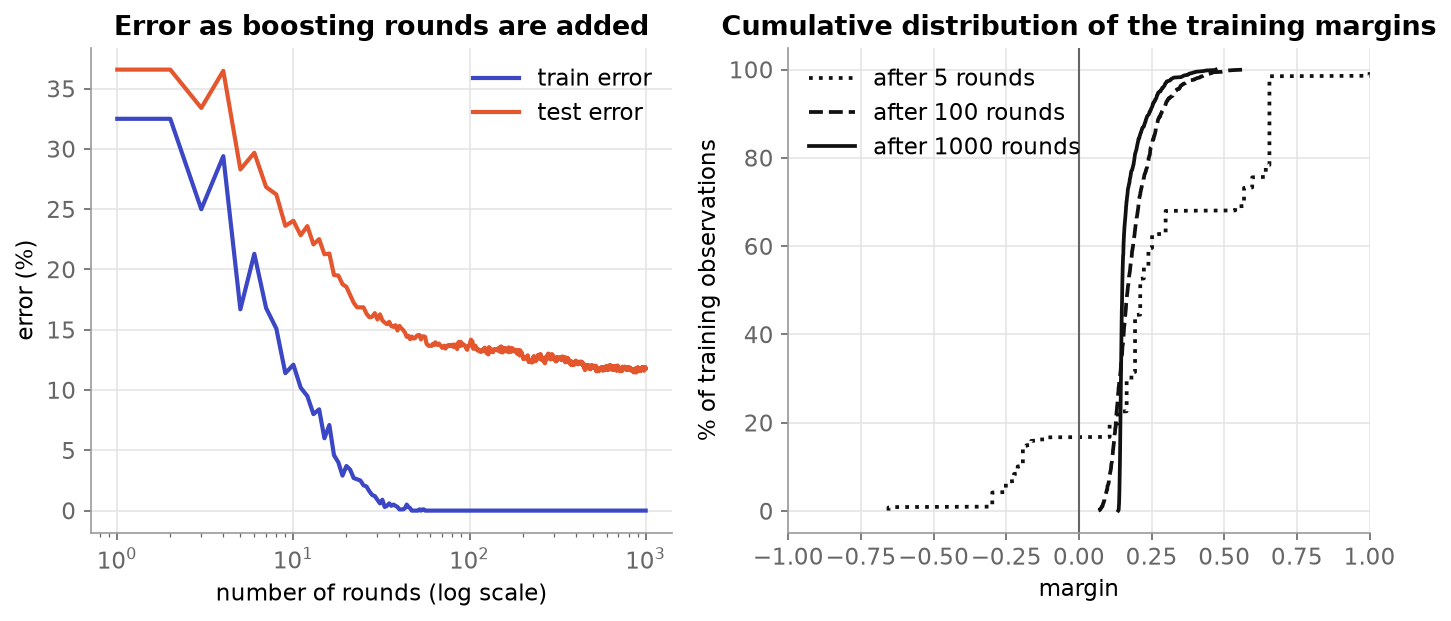

## Gradient Boosting (XGBoost)

Another very popular boosting algorithm is gradient boosting, which works a little differently from AdaBoost. Let $X$ be our training data and $y$ the target variable. Gradient boosting trains a sequence of models, written $F_1, ..., F_m$, whose goal is to predict $y$ as accurately as possible.
The algorithm starts by predicting $y$ with $F_1$, which gives:
$\hat{F_1}(X) = \hat{y}_1$ where $\hat{F_1}$ is the trained version of model $F_1$
This model isn't necessarily very accurate at this point, so we may want to add another model to predict $y$ better. Let's call this new predictor $f_1$. The idea is to solve:
$F_2(X) = \hat{F_1}(X) + f_1(X) = y$
$f_1(X) = y - \hat{F_1}(X) = y - \hat{y}_1 = \epsilon_1$
So the idea is to train the new predictor $f_1$ to predict the residuals $\epsilon_1$ of the first model, and not $y$ directly.
The sequence of models is built iteratively with the following equation:
$F_{i+1} = \hat{F_{i}} + f_i$ 
where $f_i$ is trained on the residuals of $F_i$, written $\epsilon_i$.

